# Import

In [72]:
import kagglehub
import pandas as pd

import os
import shutil
import time
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import pyAudioAnalysis
try:
    from tqdm import tqdm
except ImportError:
    tqdm = None

pd.set_option('display.max_columns', None)

# Show all rows
pd.set_option('display.max_rows', None)

# Sampling

In [89]:
sample_class_length = 2500

In [90]:
df_train_files = pd.read_csv('../data/ASVspoof5.train.metadata.txt', header = None).rename(columns = {0:'file_full_name'})
df_train_files['y'] = df_train_files['file_full_name'].apply(lambda x: 1 if 'spoof' in x else 0)
df_train_files['file_name'] = df_train_files['file_full_name'].apply(lambda x: x.split(' ')[1] + '.flac')
print("Balanceamento original: \n", df_train_files.y.value_counts()/len(df_train_files))
df_train_0 = df_train_files[df_train_files.y == 0].sample(n=sample_class_length, random_state=42)
df_train_1 = df_train_files[df_train_files.y == 1].sample(n=sample_class_length, random_state=42)
df_train_files = pd.concat([df_train_0, df_train_1])
print("Balanceamento após amostragem: \n", df_train_files.y.value_counts()/len(df_train_files))
print('Tamanho do dataset de treino: ', len(df_train_files))
df_train_files.head()

Balanceamento original: 
 y
1    0.896922
0    0.103078
Name: count, dtype: float64
Balanceamento após amostragem: 
 y
0    0.5
1    0.5
Name: count, dtype: float64
Tamanho do dataset de treino:  5000


,file_full_name,y,file_name
76181,T_4075 T_0000076181 M - bonafide bonafide,0,T_0000076181.flac
27303,T_4700 T_0000027303 M - bonafide bonafide,0,T_0000027303.flac
96453,T_1570 T_0000096453 M - bonafide bonafide,0,T_0000096453.flac
134567,T_3229 T_0000134567 M - bonafide bonafide,0,T_0000134567.flac
86224,T_1308 T_0000086224 F - bonafide bonafide,0,T_0000086224.flac


In [91]:
df_dev_files = pd.read_csv('../data/ASVspoof5.dev.metadata.txt', header = None).rename(columns = {0:'file_full_name'})
df_dev_files['y'] = df_dev_files['file_full_name'].apply(lambda x: 1 if 'spoof' in x else 0)
df_dev_files['file_name'] = df_dev_files['file_full_name'].apply(lambda x: x.split(' ')[1] + '.flac')
print("Balanceamento original: \n", df_dev_files.y.value_counts()/len(df_dev_files))
df_dev_0 = df_dev_files[df_dev_files.y == 0].sample(n=sample_class_length, random_state=42)
df_dev_1 = df_dev_files[df_dev_files.y == 1].sample(n=sample_class_length, random_state=42)
df_dev_files = pd.concat([df_dev_0, df_dev_1])
print("Balanceamento após amostragem: \n", df_dev_files.y.value_counts()/len(df_dev_files))
print('Tamanho do dataset de treino: ', len(df_dev_files))
df_dev_files.head()

Balanceamento original: 
 y
1    0.777694
0    0.222306
Name: count, dtype: float64
Balanceamento após amostragem: 
 y
0    0.5
1    0.5
Name: count, dtype: float64
Tamanho do dataset de treino:  5000


,file_full_name,y,file_name
31376,D_4619 D_0000658897 M - bonafide bonafide,0,D_0000658897.flac
11069,D_0430 D_0000232450 M - bonafide bonafide,0,D_0000232450.flac
415,D_4737 D_0000008716 M - bonafide bonafide,0,D_0000008716.flac
50375,D_2529 D_0001057876 F - bonafide bonafide,0,D_0001057876.flac
78043,D_3278 D_0001638904 F - bonafide bonafide,0,D_0001638904.flac


# Download

In [7]:
def _caminho_no_dataset(nome_arquivo: str) -> str:
    """Caminho do arquivo dentro do dataset do Kaggle.
    Treino (T_...) fica em flac_T/flac_T/<arquivo>, dev (D_...) em flac_D/flac_D/<arquivo>."""
    prefixo = nome_arquivo.split('_')[0]  # 'T' ou 'D'
    return f"flac_{prefixo}/flac_{prefixo}/{nome_arquivo}"


def baixar_arquivos_amostrados(
    dfs: dict,
    dataset_handle: str = "ulianazb/asvspoof-2024",
    dest_dir: str = "../data/flac_sample",
    col_file_name: str = "file_name",
    max_workers: int = 4,
    max_tentativas: int = 3,
    limite: int | None = None,
    forcar: bool = False,
) -> pd.DataFrame:
    """
    Baixa, via kagglehub, apenas os arquivos .flac amostrados nos dataframes
    passados (ex.: {"train": df_train_files, "dev": df_dev_files}), sem baixar
    o dataset inteiro do Kaggle.

    Parameters
    ----------
    dfs : dict[str, pd.DataFrame]
        Rótulo do split -> dataframe amostrado (precisa ter a coluna `col_file_name`).
    dataset_handle : str
        Dataset no Kaggle, no formato "owner/dataset".
    dest_dir : str
        Pasta local onde os arquivos baixados serão organizados (uma subpasta por split).
    col_file_name : str
        Nome da coluna com o nome do arquivo .flac.
    max_workers : int
        Downloads em paralelo.
    max_tentativas : int
        Tentativas por arquivo antes de desistir (falhas transitórias de rede).
    limite : int, opcional
        Se definido, baixa só os N primeiros arquivos de cada split (bom para testar).
    forcar : bool
        Se True, baixa de novo mesmo que o arquivo já exista localmente.

    Returns
    -------
    pd.DataFrame
        Relatório com uma linha por arquivo: split, file_name, status
        ("ok" / "já existia" / "falhou"), caminho_no_dataset, destino, erro.
    """
    dest_dir = Path(dest_dir)

    def _baixar_um(split, nome_arquivo, destino_split_dir):
        destino = destino_split_dir / nome_arquivo
        if destino.exists() and not forcar:
            return {"split": split, "file_name": nome_arquivo, "status": "já existia",
                    "caminho_no_dataset": None, "destino": str(destino), "erro": None}

        caminho = _caminho_no_dataset(nome_arquivo)
        ultimo_erro = None
        for _ in range(max_tentativas):
            try:
                caminho_local = kagglehub.dataset_download(dataset_handle, path=caminho)
                destino_split_dir.mkdir(parents=True, exist_ok=True)
                shutil.copy2(caminho_local, destino)
                return {"split": split, "file_name": nome_arquivo, "status": "ok",
                        "caminho_no_dataset": caminho, "destino": str(destino), "erro": None}
            except Exception as e:
                ultimo_erro = e
                time.sleep(0.5 + random.random())
        return {"split": split, "file_name": nome_arquivo, "status": "falhou",
                "caminho_no_dataset": caminho, "destino": None, "erro": str(ultimo_erro)}

    tarefas = []
    for split, df in dfs.items():
        nomes = df[col_file_name].drop_duplicates().tolist()
        if limite:
            nomes = nomes[:limite]
        destino_split_dir = dest_dir / split
        for nome_arquivo in nomes:
            tarefas.append((split, nome_arquivo, destino_split_dir))

    print(f"Baixando {len(tarefas)} arquivos de '{dataset_handle}' para '{dest_dir}'...")

    resultados = []
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futuros = [executor.submit(_baixar_um, *t) for t in tarefas]
        iterador = as_completed(futuros)
        if tqdm:
            iterador = tqdm(iterador, total=len(futuros))
        for futuro in iterador:
            resultados.append(futuro.result())

    relatorio_df = pd.DataFrame(resultados)
    ok = (relatorio_df["status"] == "ok").sum()
    existia = (relatorio_df["status"] == "já existia").sum()
    falhou = (relatorio_df["status"] == "falhou").sum()
    print(f"Concluído: {ok} baixados, {existia} já existiam, {falhou} falharam.")
    if falhou:
        print("Exemplos de falha:")
        print(relatorio_df[relatorio_df.status == "falhou"].head())

    return relatorio_df

In [ ]:
%%time
relatorio = baixar_arquivos_amostrados(
    {"train": df_train_files, "dev": df_dev_files},
    dest_dir="../data/flac_sample",
)
relatorio

In [10]:
relatorio.status.value_counts()

status
ok        6503
falhou    3497
Name: count, dtype: int64

In [12]:
pd.crosstab(relatorio.status, relatorio.split, margins=True, margins_name="Total")

split,dev,train,Total
status,,,
falhou,3497,0,3497
ok,1503,5000,6503
Total,5000,5000,10000


In [ ]:
%%time
# Remanescentes
df_dev_files_remaining = df_dev_files[~df_dev_files.file_name.isin(relatorio.query("status == 'ok'")["file_name"])]
relatorio_remaining = baixar_arquivos_amostrados(
    {"dev": df_dev_files_remaining},
    dest_dir="../data/flac_sample",
)
relatorio_remaining

In [17]:
relatorio_remaining.status.value_counts()

status
ok    3497
Name: count, dtype: int64

# Dataprep

In [64]:
import numpy as np

# Restaura aliases removidos no NumPy 2.0, usados por código antigo
# (pyAudioAnalysis entre eles) que ainda escreve numpy.Inf / numpy.NaN etc.
for _name, _value in [("Inf", np.inf), ("Infinity", np.inf),
                       ("NaN", np.nan), ("NAN", np.nan)]:
    if not hasattr(np, _name):
        setattr(np, _name, _value)

In [101]:
from pyAudioAnalysis import audioBasicIO
import soundfile as sf
from pyAudioAnalysis import ShortTermFeatures
from pyAudioAnalysis import MidTermFeatures
import numpy as np
from pathlib import Path
# Show all columns


SHORT_WIN = 0.050    # 50 ms
SHORT_STEP = 0.025   # 25 ms (50% overlap)

DATA_PREP_DIR = Path("../data/flac_sample/data_prep")
DATA_PREP_DIR.mkdir(parents=True, exist_ok=True)

/Users/arthurmoriggipimenta/Desktop/doutorado/ia-adversarial/env_aiadv/lib/python3.13/site-packages/pydub/utils.py:170: RuntimeWarning: Couldn't find ffmpeg or avconv - defaulting to ffmpeg, but may not work
  warn("Couldn't find ffmpeg or avconv - defaulting to ffmpeg, but may not work", RuntimeWarning)


In [66]:
def read_audio_mono(path, dtype="int16"):
    """Lê o .flac com soundfile e garante sinal mono."""
    x, Fs = sf.read(str(path), dtype=dtype)
    if x.ndim > 1:
        x = x.mean(axis=1).astype(dtype)
    return x, Fs


import sys
_EPS = sys.float_info.epsilon


def _harmonic_fixed(frame, sampling_rate):
    """
    Mesma lógica de ShortTermFeatures.harmonic, só com um fix: a lib usa
    np.round(...) (retorna float) direto como shape de np.zeros, o que
    quebra em numpy >= 2 com TypeError. Aqui convertemos pra int.
    """
    m = int(np.round(0.016 * sampling_rate)) - 1  # <- fix
    r = np.correlate(frame, frame, mode="full")

    g = r[len(frame) - 1]
    r = r[len(frame):-1]

    a, = np.nonzero(np.diff(np.sign(r)))
    m0 = (len(r) - 1) if len(a) == 0 else a[0]
    if m > len(r):
        m = len(r) - 1

    gamma = np.zeros((m), dtype=np.float64)
    cumulative_sum = np.cumsum(frame ** 2)
    gamma[m0:m] = r[m0:m] / (np.sqrt((g * cumulative_sum[m:m0:-1])) + _EPS)

    zcr = ShortTermFeatures.zero_crossing_rate(gamma)

    if zcr > 0.15:
        hr, f0 = 0.0, 0.0
    else:
        if len(gamma) == 0:
            hr, blag = 1.0, 0.0
        else:
            hr = np.max(gamma)
            blag = np.argmax(gamma)
        f0 = sampling_rate / (blag + _EPS)
        if f0 > 5000:
            f0 = 0.0
        if hr < 0.1:
            f0 = 0.0

    return hr, f0

def harmonic_features_per_frame(signal, Fs, window, step):
    """
    Replica o janelamento usado por ShortTermFeatures.feature_extraction
    e calcula, por frame, (hr, f0) via _harmonic_fixed.
    """
    window, step = int(window), int(step)
    n_samples = len(signal)
    pos = 0
    hrs, f0s = [], []
    while pos + window - 1 < n_samples:
        frame = signal[pos: pos + window]
        hr, f0 = _harmonic_fixed(frame, Fs)
        hrs.append(hr)
        f0s.append(f0)
        pos += step
    return np.array([hrs, f0s])

def extract_all_features(path, short_win=SHORT_WIN, short_step=SHORT_STEP):
    """
    Para um único áudio, retorna:
      sequence  : (n_frames, 70) -> p/ a rede recorrente
                  (68 features padrão + harmonic_ratio + f0, por frame)
      tabular   : (142,)         -> p/ o gradient boosting
                  (média + desvio padrão das 70 features ao longo do tempo + bpm + beat_ratio)
      col_names : nomes das 142 colunas, sempre na mesma ordem
    """
    x, Fs = read_audio_mono(path)

    # 68 features clássicas (short-term, já com deltas)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, short_win * Fs, short_step * Fs)

    # +2 features harmônicas por frame
    H = harmonic_features_per_frame(x, Fs, short_win * Fs, short_step * Fs)
    f_names_ext = list(f_names) + ["harmonic_ratio", "f0"]

    n_frames = min(F.shape[1], H.shape[1])  # segurança p/ possível diferença de 1 frame
    F_ext = np.vstack([F[:, :n_frames], H[:, :n_frames]])  # (70, n_frames)

    # +2 features de beat (bpm, confiança) p/ o áudio inteiro
    # atenção: beat_extraction espera o passo em SEGUNDOS, não em amostras
    bpm, beat_ratio = MidTermFeatures.beat_extraction(F, short_step)

    sequence = F_ext.T.astype(np.float32)  # (n_frames, 70) -> formato da LSTM

    agg_mean = F_ext.mean(axis=1)
    agg_std = F_ext.std(axis=1)
    tabular = np.concatenate([agg_mean, agg_std, [bpm, beat_ratio]])  # (142,)

    col_names = (
        [f"{n}_mean" for n in f_names_ext]
        + [f"{n}_std" for n in f_names_ext]
        + ["bpm", "beat_ratio"]
    )
    return sequence, tabular, col_names

In [67]:
def build_and_save_split(df_files, flac_dir, split_name, out_dir=DATA_PREP_DIR):
    flac_dir = Path(flac_dir)
    sequences, seq_labels, seq_ids = [], [], []
    tabular_rows = []
    col_names = None
    falhas = []

    iterator = df_files.itertuples()
    if tqdm is not None:
        iterator = tqdm(iterator, total=len(df_files), desc=f"Extraindo features ({split_name})")

    for row in iterator:
        path = flac_dir / row.file_name
        if not path.exists():
            falhas.append((row.file_name, "arquivo não encontrado"))
            continue
        try:
            sequence, tabular, names = extract_all_features(path)
        except Exception as e:
            falhas.append((row.file_name, str(e)))
            continue

        if col_names is None:
            col_names = names

        sequences.append(sequence)
        seq_labels.append(row.y)
        seq_ids.append(row.file_name)
        tabular_rows.append({"file_name": row.file_name, "y": row.y, **dict(zip(names, tabular))})

    df_tabular = pd.DataFrame(tabular_rows)
    df_tabular.to_pickle(out_dir / f"{split_name}_tabular.pkl")

    np.savez(
        out_dir / f"{split_name}_sequences.npz",
        sequences=np.array(sequences, dtype=object),  # comprimento variável por áudio
        labels=np.array(seq_labels),
        ids=np.array(seq_ids),
    )

    print(f"[{split_name}] ok: {len(df_tabular)} | falhas: {len(falhas)}")
    if falhas:
        print(f"[{split_name}] primeiras falhas:", falhas[:5])

    return df_tabular, falhas

In [70]:
%%time
df_train_tabular, falhas_train = build_and_save_split(
    df_train_files, "../data/flac_sample/train", "train"
)

df_dev_tabular, falhas_dev = build_and_save_split(
    df_dev_files, "../data/flac_sample/dev", "dev"
)

Extraindo features (train):   0%|          | 0/5000 [00:00<?, ?it/s]/var/folders/vn/qwxg6g2j3x363x3hjdxtfnpr0000gn/T/ipykernel_24076/149953503.py:32: RuntimeWarning: invalid value encountered in sqrt
  gamma[m0:m] = r[m0:m] / (np.sqrt((g * cumulative_sum[m:m0:-1])) + _EPS)
Extraindo features (train): 100%|██████████| 5000/5000 [16:47<00:00,  4.96it/s]


[train] ok: 5000 | falhas: 0


Extraindo features (dev): 100%|██████████| 5000/5000 [08:59<00:00,  9.26it/s]


[dev] ok: 5000 | falhas: 0
CPU times: user 25min 17s, sys: 21.1 s, total: 25min 38s
Wall time: 25min 48s


# EDA

In [175]:
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
FIG_DIR = Path("../images")
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [75]:
feat_names = [x for x in df_train_tabular.columns if x not in ["file_name", "y"]]

In [73]:
df_train_tabular.head()

,file_name,y,zcr_mean,energy_mean,energy_entropy_mean,spectral_centroid_mean,spectral_spread_mean,spectral_entropy_mean,spectral_flux_mean,spectral_rolloff_mean,...,delta chroma_8_std,delta chroma_9_std,delta chroma_10_std,delta chroma_11_std,delta chroma_12_std,delta chroma_std_std,harmonic_ratio_std,f0_std,bpm,beat_ratio
0,T_0000076181.flac,0,0.128440,0.007633,2.778167,0.205441,0.192579,0.920152,0.008453,0.212660,...,0.005193,0.014469,0.017941,0.017050,0.010427,0.010284,NaN,638.677595,342.857143,0.087703
1,T_0000027303.flac,0,0.253794,0.007512,2.799482,0.312548,0.213547,1.111780,0.009883,0.367103,...,0.008497,0.010218,0.022294,0.016437,0.011335,0.010804,NaN,686.773560,218.181818,0.071104
2,T_0000096453.flac,0,0.081325,0.019445,2.872567,0.164860,0.200678,0.520839,0.011894,0.123958,...,0.002648,0.015267,0.024485,0.029229,0.007837,0.014841,NaN,815.723956,266.666667,0.084138
3,T_0000134567.flac,0,0.083204,0.020164,2.867838,0.171158,0.194186,0.544899,0.009120,0.129557,...,0.003750,0.005197,0.014438,0.035182,0.008387,0.014182,NaN,685.641253,218.181818,0.076602
4,T_0000086224.flac,0,0.163026,0.014801,2.998055,0.258878,0.222554,0.923705,0.008259,0.257678,...,0.004917,0.013295,0.011897,0.019407,0.006555,0.010905,NaN,701.266891,300.000000,0.076923


In [79]:
df_train_tabular[feat_names].describe().T

,count,mean,std,min,25%,50%,75%,max
zcr_mean,5000.0,1.511438e-01,0.041507,2.571693e-02,1.224116e-01,1.467445e-01,1.751663e-01,0.410002
energy_mean,5000.0,1.430573e-02,0.007829,4.088436e-04,8.712600e-03,1.287597e-02,1.822908e-02,0.071780
energy_entropy_mean,5000.0,2.861597e+00,0.090139,2.437423e+00,2.804414e+00,2.865901e+00,2.927688e+00,3.160398
spectral_centroid_mean,5000.0,2.384208e-01,0.042562,1.162837e-01,2.087448e-01,2.317836e-01,2.624421e-01,0.473556
spectral_spread_mean,5000.0,2.095374e-01,0.015309,1.669059e-01,1.991164e-01,2.082307e-01,2.185153e-01,0.279735
spectral_entropy_mean,5000.0,9.363315e-01,0.282796,9.536261e-02,7.388253e-01,8.942993e-01,1.086119e+00,2.320969
spectral_flux_mean,5000.0,8.534458e-03,0.002448,2.738175e-03,7.007934e-03,8.260198e-03,9.674694e-03,0.032505
spectral_rolloff_mean,5000.0,2.393258e-01,0.072774,3.422174e-02,1.891044e-01,2.285540e-01,2.800055e-01,0.673225
mfcc_1_mean,5000.0,-2.813784e+01,1.548838,-4.102417e+01,-2.898635e+01,-2.784843e+01,-2.703073e+01,-24.327921
mfcc_2_mean,5000.0,2.130495e+00,0.542438,-3.624640e-01,1.845648e+00,2.223588e+00,2.503738e+00,3.777517


In [80]:
to_drop = ['harmonic_ratio_std', 'harmonic_ratio_mean']
feat_names = [x for x in feat_names if x not in to_drop]

In [74]:
from sklearn.feature_selection import mutual_info_classif

X_feat = df_train_tabular[feat_names]
y_bin = df_train_tabular["y"]

# mutual_info_classif não aceita NaN -- preenche só pra esse cálculo (não altera X_feat original)
nan_count = X_feat.isna().sum().sum()
if nan_count > 0:
    print(f"Aviso: {nan_count} valores NaN nas features -- preenchendo com a mediana só para este cálculo.")
X_feat_mi = X_feat.fillna(X_feat.median())

pearson = X_feat.apply(lambda col: col.corr(y_bin, method="pearson"))
spearman = X_feat.apply(lambda col: col.corr(y_bin, method="spearman"))
mi = pd.Series(
    mutual_info_classif(X_feat_mi, y_bin, random_state=42),
    index=feat_names,
)

df_rank = pd.DataFrame({"pearson": pearson, "spearman": spearman, "mutual_info": mi})
df_rank["pearson_abs"] = df_rank["pearson"].abs()
df_rank["spearman_abs"] = df_rank["spearman"].abs()
df_rank.sort_values("mutual_info", ascending=False).head(15)

,pearson,spearman,mutual_info,pearson_abs,spearman_abs
delta mfcc_9_std,-0.582899,-0.600645,0.208073,0.582899,0.600645
mfcc_1_mean,0.544495,0.595464,0.206569,0.544495,0.595464
delta mfcc_10_std,-0.555848,-0.570219,0.204980,0.555848,0.570219
mfcc_10_std,-0.518891,-0.571744,0.192207,0.518891,0.571744
mfcc_9_std,-0.529270,-0.550762,0.172234,0.529270,0.550762
mfcc_1_std,-0.412474,-0.537246,0.170924,0.412474,0.537246
delta mfcc_8_std,-0.511244,-0.514508,0.161305,0.511244,0.514508
mfcc_8_std,-0.512443,-0.529603,0.160140,0.512443,0.529603
mfcc_11_std,-0.411051,-0.460133,0.151007,0.411051,0.460133
delta mfcc_7_std,-0.501049,-0.514800,0.145059,0.501049,0.514800


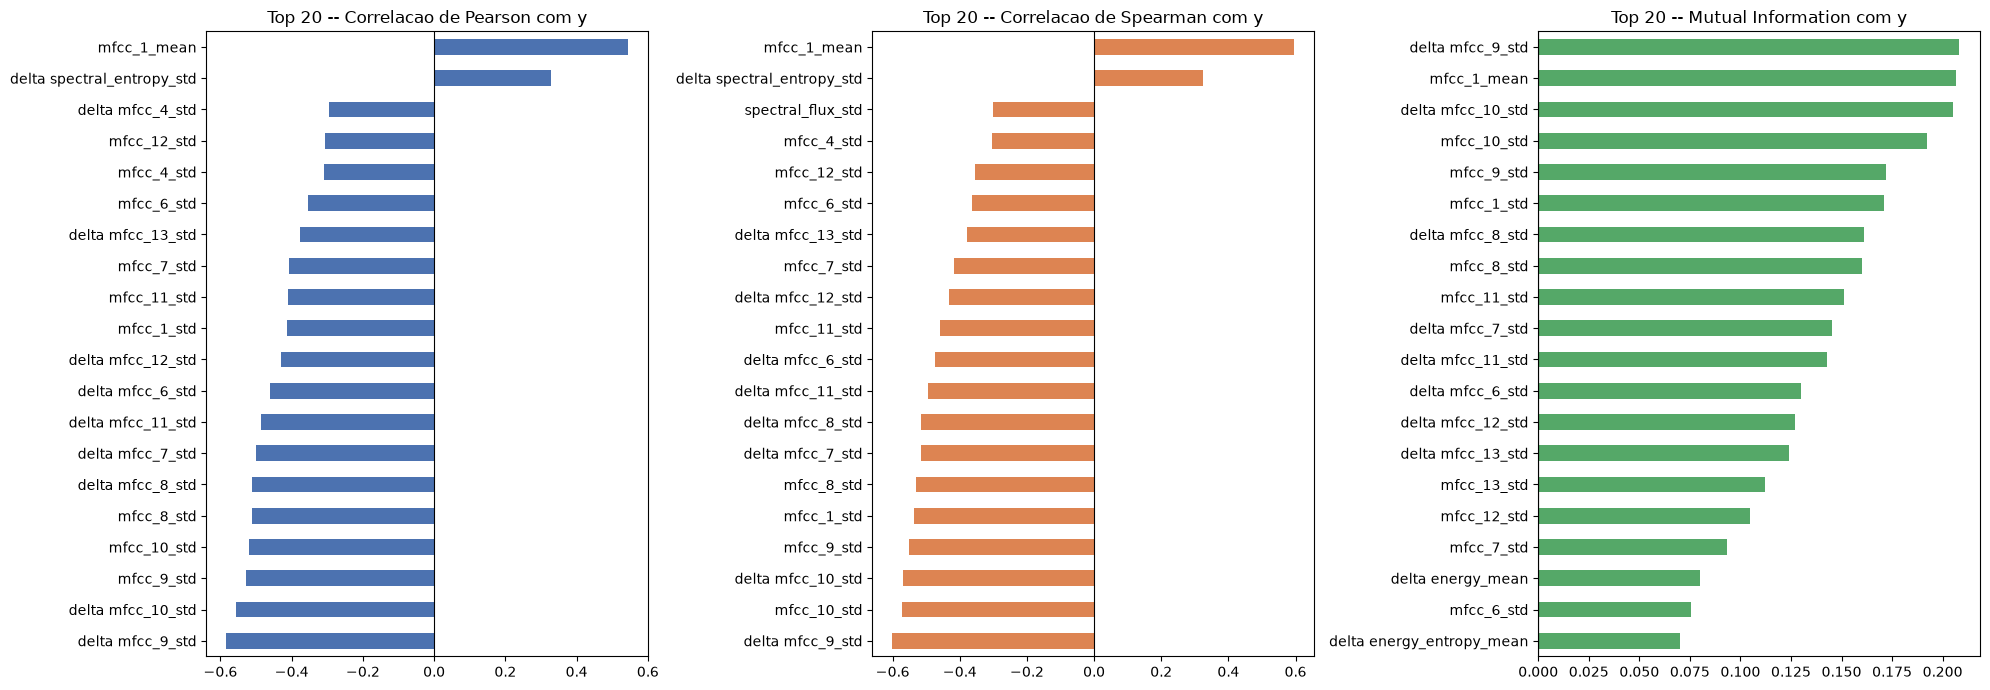

In [176]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

df_rank.sort_values("pearson_abs", ascending=False).head(20)["pearson"].sort_values().plot(
    kind="barh", ax=axes[0], color="#4C72B0", title="Top 20 -- Correlacao de Pearson com y"
)
df_rank.sort_values("spearman_abs", ascending=False).head(20)["spearman"].sort_values().plot(
    kind="barh", ax=axes[1], color="#DD8452", title="Top 20 -- Correlacao de Spearman com y"
)
df_rank.sort_values("mutual_info", ascending=False).head(20)["mutual_info"].sort_values().plot(
    kind="barh", ax=axes[2], color="#55A868", title="Top 20 -- Mutual Information com y"
)

for ax in axes:
    ax.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_top_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

In [177]:
corr_matrix = X_feat.corr(method="pearson").abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))

pares_colineares = (
    upper.stack()
    .rename("pearson_abs")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)
pares_colineares = pares_colineares[pares_colineares["pearson_abs"] > 0.8].sort_values(
    "pearson_abs", ascending=False
)

print(f"{len(pares_colineares)} pares de features com |pearson| > 0.8 (de {len(feat_names)} features)")
pares_colineares

93 pares de features com |pearson| > 0.8 (de 140 features)


,feature_1,feature_2,pearson_abs
10609,spectral_flux_std,delta spectral_flux_std,0.984493
13711,chroma_8_std,delta chroma_8_std,0.969376
12865,chroma_2_std,delta chroma_2_std,0.958755
7,zcr_mean,spectral_rolloff_mean,0.957510
9904,energy_std,delta energy_std,0.955478
14275,chroma_12_std,delta chroma_12_std,0.954892
427,spectral_centroid_mean,spectral_rolloff_mean,0.954680
13852,chroma_9_std,delta chroma_9_std,0.954345
13429,chroma_6_std,delta chroma_6_std,0.952246
12724,chroma_1_std,delta chroma_1_std,0.950419


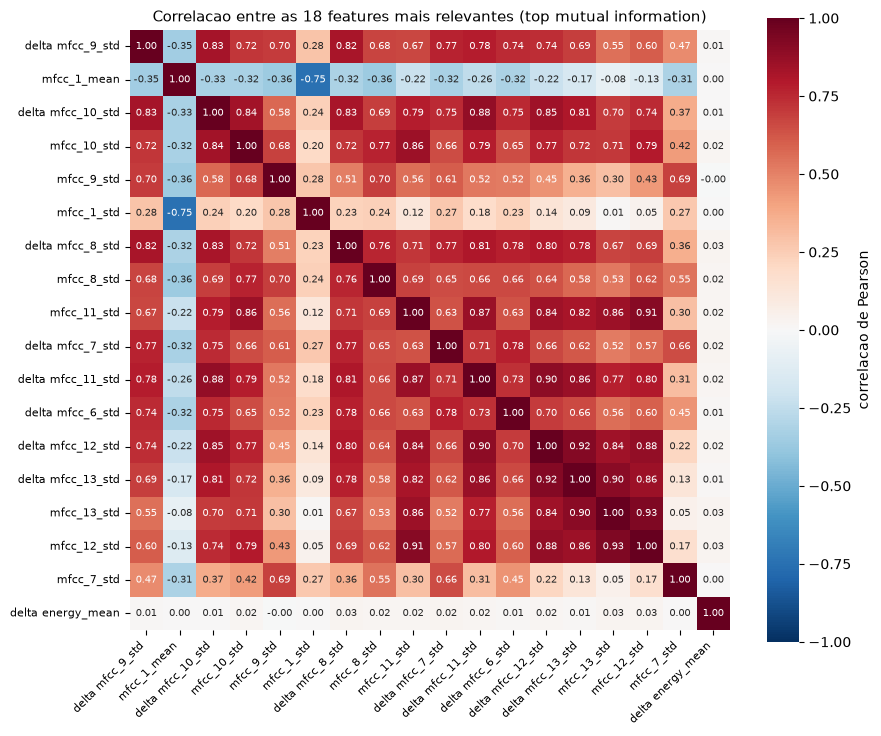

In [179]:
heatmap_feats = df_rank.sort_values("mutual_info", ascending=False).head(18).index.tolist()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    X_feat[heatmap_feats].corr(method="pearson"),
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    square=True, cbar_kws={"label": "correlacao de Pearson"}, ax=ax,
)
ax.set_title("Correlacao entre as 18 features mais relevantes (top mutual information)", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## O que significam as features mais relevantes

In [77]:
FEATURE_BASE_GLOSSARY = {
    "zcr": "Taxa de cruzamentos por zero -- quao rapido o sinal oscila entre positivo e negativo. "
           "Fricativas/ruido tendem a ZCR alto; sons tonais graves, a ZCR baixo.",
    "energy": "Energia (potencia) do frame -- intensidade/volume do sinal naquele instante.",
    "energy_entropy": "Entropia da distribuicao de energia dentro do frame -- baixa em transientes/picos "
                       "abruptos, alta quando a energia esta espalhada uniformemente.",
    "spectral_centroid": "Centro de massa do espectro de frequencia -- correlaciona com o brilho percebido do som.",
    "spectral_spread": "Dispersao do espectro em torno do centroide espectral -- quao concentrada ou "
                        "espalhada a energia esta nas frequencias.",
    "spectral_entropy": "Entropia da distribuicao de energia no espectro -- baixa quando o espectro e "
                         "concentrado/tonal, alta quando e espalhado/ruidoso.",
    "spectral_flux": "Variacao do espectro entre frames consecutivos -- quao rapido o conteudo espectral muda no tempo.",
    "spectral_rolloff": "Frequencia abaixo da qual esta concentrada a maior parte da energia espectral -- "
                         "indica se o som e mais grave ou mais agudo.",
    "chroma_std": "Desvio padrao da energia entre as 12 classes de altura musical (chroma) -- quao "
                  "concentrada e a energia tonal.",
    "harmonic_ratio": "Razao harmonica -- quao periodico/harmonico e o frame (alto em vogais sustentadas, "
                       "baixo em ruido/silencio/consoantes nao vozeadas).",
    "f0": "Frequencia fundamental estimada (pitch) -- tom da voz; vocoders/sintetizadores podem produzir "
          "contornos de pitch diferentes dos da voz humana.",
    "bpm": "Tempo estimado (batidas por minuto) do audio inteiro -- periodicidade ritmica/artefatos de "
           "processamento ao longo de todo o arquivo.",
    "beat_ratio": "Confianca da estimativa de bpm -- quao concentrado esta o histograma usado para estimar o bpm.",
}


def explica_feature(nome_coluna):
    base = nome_coluna
    agregacao = None
    if base.endswith("_mean"):
        base, agregacao = base[: -len("_mean")], "media ao longo do audio"
    elif base.endswith("_std"):
        base, agregacao = base[: -len("_std")], "desvio padrao ao longo do audio (variabilidade temporal)"

    is_delta = base.startswith("delta ")
    if is_delta:
        base = base[len("delta "):]

    if base.startswith("mfcc_"):
        numero = base.split("_")[1]
        desc = (f"Coeficiente cepstral de Mel-frequencia no {numero} -- parte da representacao "
                "compacta do timbre/envelope espectral (muito usada em reconhecimento de voz/locutor).")
    elif base.startswith("chroma_") and base != "chroma_std":
        numero = base.split("_")[1]
        desc = f"Energia na classe de altura musical (chroma) no {numero} de 12 -- conteudo tonal/harmonico do som."
    else:
        desc = FEATURE_BASE_GLOSSARY.get(base, "(sem descricao cadastrada)")

    prefixo = "Variacao quadro-a-quadro (delta) de -- " if is_delta else ""
    sufixo = f" [{agregacao}]" if agregacao else ""
    return f"{prefixo}{desc}{sufixo}"


top_pearson = df_rank.sort_values("pearson_abs", ascending=False).head(10).index.tolist()
top_spearman = df_rank.sort_values("spearman_abs", ascending=False).head(10).index.tolist()
top_mi = df_rank.sort_values("mutual_info", ascending=False).head(10).index.tolist()

top_features = list(dict.fromkeys(top_pearson + top_spearman + top_mi))

print("Features mais relevantes (uniao do top 10 de cada criterio) e o que significam:\n")
for feat in top_features:
    print(f"- {feat}: {explica_feature(feat)}")

Features mais relevantes (uniao do top 10 de cada criterio) e o que significam:

- delta mfcc_9_std: Variacao quadro-a-quadro (delta) de -- Coeficiente cepstral de Mel-frequencia no 9 -- parte da representacao compacta do timbre/envelope espectral (muito usada em reconhecimento de voz/locutor). [desvio padrao ao longo do audio (variabilidade temporal)]
- delta mfcc_10_std: Variacao quadro-a-quadro (delta) de -- Coeficiente cepstral de Mel-frequencia no 10 -- parte da representacao compacta do timbre/envelope espectral (muito usada em reconhecimento de voz/locutor). [desvio padrao ao longo do audio (variabilidade temporal)]
- mfcc_1_mean: Coeficiente cepstral de Mel-frequencia no 1 -- parte da representacao compacta do timbre/envelope espectral (muito usada em reconhecimento de voz/locutor). [media ao longo do audio]
- mfcc_9_std: Coeficiente cepstral de Mel-frequencia no 9 -- parte da representacao compacta do timbre/envelope espectral (muito usada em reconhecimento de voz/locutor). [d

# Gradient Boosting

In [78]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
import numpy as np
import pandas as pd
import lightgbm as lgb
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)  # evita log gigante por trial

RANDOM_STATE = 42
EARLY_STOPPING_ROUNDS = 3
MAX_BOOST_ROUNDS = 10_000  # "livre pra crescer" -- o early stopping decide onde parar
N_TRIALS = 50

In [79]:
df_train_tabular = pd.read_pickle('../data/flac_sample/data_prep/train_tabular.pkl')
df_dev_tabular = pd.read_pickle('../data/flac_sample/data_prep/dev_tabular.pkl')
feat_names = [x for x in df_train_tabular.columns if x not in ["file_name", "y"]]
to_drop = ['harmonic_ratio_std', 'harmonic_ratio_mean']
feat_names = [x for x in feat_names if x not in to_drop]

In [80]:
X = df_train_tabular[feat_names]
y = df_train_tabular["y"]

# holdout de validação -- usado SÓ pra early stopping / seleção de hiperparâmetros.
# o dev/test (df_dev_tabular) fica intocado até a avaliação final.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)

In [81]:
def objective(trial):
    params = {
        "objective": "binary",
        "n_estimators": MAX_BOOST_ROUNDS,  # "ilimitado" -- o early stopping decide onde parar
        "random_state": RANDOM_STATE,
        "verbosity": -1,

        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 16),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),      # min_data_in_leaf
        "min_child_weight": trial.suggest_float("min_child_weight", 1e-3, 10.0, log=True),  # min_sum_hessian_in_leaf
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),    # feature_fraction
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),                 # bagging_fraction
        "subsample_freq": trial.suggest_int("subsample_freq", 1, 10),            # bagging_freq
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),     # lambda_l1
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),   # lambda_l2
        "min_split_gain": trial.suggest_float("min_split_gain", 1e-8, 1.0, log=True),  # min_gain_to_split
        "max_bin": trial.suggest_int("max_bin", 63, 255),
    }

    model = LGBMClassifier(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="auc",
        callbacks=[
            lgb.early_stopping(stopping_rounds=EARLY_STOPPING_ROUNDS, verbose=False),
            lgb.log_evaluation(period=0),
        ],
    )

    best_auc = model.best_score_["valid_0"]["auc"]
    trial.set_user_attr("best_iteration", model.best_iteration_)  # guarda o n_estimators dessa rodada

    return best_auc

In [82]:
%%time
sampler = TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print("Melhor AUC (validação):", study.best_value)
print("Melhor n_estimators:", study.best_trial.user_attrs["best_iteration"])
print("Melhores hiperparâmetros:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

  0%|          | 0/50 [00:00<?, ?it/s]/Users/arthurmoriggipimenta/Desktop/doutorado/ia-adversarial/env_aiadv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 0. Best value: 0.953444:   0%|          | 0/50 [00:00<?, ?it/s]/Users/arthurmoriggipimenta/Desktop/doutorado/ia-adversarial/env_aiadv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Best trial: 1. Best value: 0.993038:   4%|▍         | 2/50 [00:00<00:05,  8.13it/s]/Users/arthurmoriggipimenta/Desktop/doutorado/ia-adversarial/env_aiadv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated,

Melhor AUC (validação): 0.9957831111111111
Melhor n_estimators: 99
Melhores hiperparâmetros:
  learning_rate: 0.10040277119302424
  max_depth: 11
  min_child_samples: 73
  min_child_weight: 0.7204968773442881
  colsample_bytree: 0.6473559135197172
  subsample: 0.6588195168334848
  subsample_freq: 3
  reg_alpha: 0.0006840624629204374
  reg_lambda: 0.0004940621360807207
  min_split_gain: 0.0003485271628481378
  max_bin: 124
CPU times: user 18.9 s, sys: 45 s, total: 1min 3s
Wall time: 16.9 s


In [83]:
params = study.best_params
params['n_estimators'] = study.best_trial.user_attrs["best_iteration"]
clf = LGBMClassifier(**params)
clf.fit(X_train, y_train)

,max_depth,11
,learning_rate,0.10040277119302424
,n_estimators,99
,min_split_gain,0.0003485271628481378
,min_child_weight,0.7204968773442881
,min_child_samples,73
,subsample,0.6588195168334848
,subsample_freq,3
,colsample_bytree,0.6473559135197172
,reg_alpha,0.0006840624629204374
,reg_lambda,0.0004940621360807207


In [84]:
df_train_tabular['pred'] = clf.predict_proba(df_train_tabular[feat_names])[:,1]
df_dev_tabular['pred'] = clf.predict_proba(df_dev_tabular[feat_names])[:,1]
print(f''' 
AUC (train): {roc_auc_score(y_train, clf.predict_proba(X_train)[:,1])}
AUC (val): {roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])}
AUC (dev): {roc_auc_score(df_dev_tabular['y'], df_dev_tabular['pred'])}
      ''')

 
AUC (train): 0.9999995570934256
AUC (val): 0.9937635555555555
AUC (dev): 0.7392286400000001
      


<Axes: ylabel='feat'>

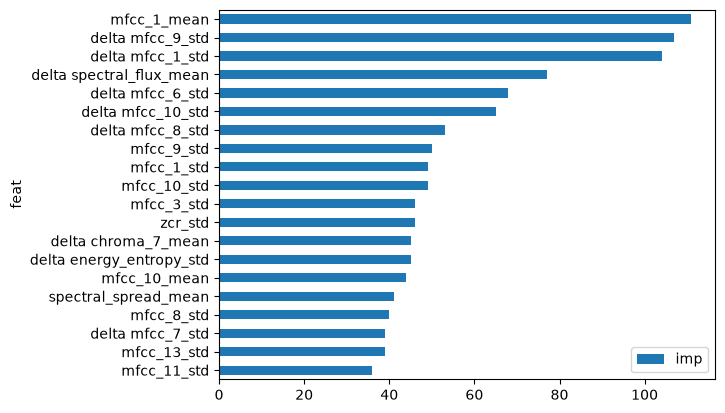

In [120]:
df_imp = pd.DataFrame()
df_imp['feat'] = feat_names 
df_imp['imp'] = clf.feature_importances_
df_imp = df_imp.sort_values('imp', ascending = False)
df_imp.head(20).sort_values('imp', ascending = True).plot(kind = 'barh', x = 'feat')

### O que o modelo aprendeu: qual caracteristica ele associa a um audio fake?



In [162]:
from pathlib import Path

FIG_DIR = Path("../images")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Figuras do relatorio serao salvas em: {FIG_DIR.resolve()}")


Figuras do relatorio serao salvas em: /Users/arthurmoriggipimenta/Desktop/doutorado/ia-adversarial/portfolio-pcs5917/images


Feature com maior importancia (split-count) no LightGBM: mfcc_1_mean


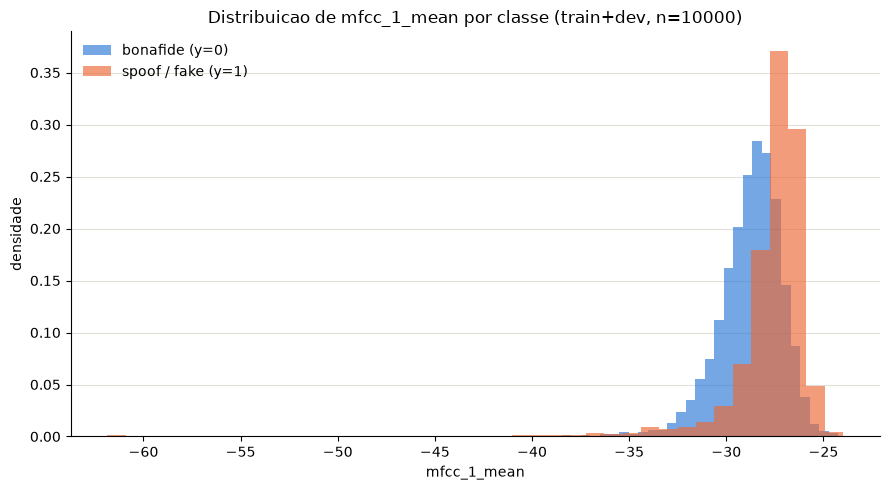

AUC usando SO mfcc_1_mean como score: 0.742  (0.5 = sem poder discriminativo isolado)


In [163]:
import matplotlib.pyplot as plt

top_feat = df_imp.sort_values('imp', ascending=False).iloc[0]['feat']
print(f"Feature com maior importancia (split-count) no LightGBM: {top_feat}")

df_all_tabular = pd.concat([
    df_train_tabular[[top_feat, 'y']],
    df_dev_tabular[[top_feat, 'y']],
])

fig, ax = plt.subplots(figsize=(9, 5))
bins = 40
ax.hist(df_all_tabular.loc[df_all_tabular['y'] == 0, top_feat], bins=bins, density=True,
        alpha=0.65, color='#2a78d6', label='bonafide (y=0)', zorder=2)
ax.hist(df_all_tabular.loc[df_all_tabular['y'] == 1, top_feat], bins=bins, density=True,
        alpha=0.65, color='#eb6834', label='spoof / fake (y=1)', zorder=2)
ax.set_xlabel(top_feat)
ax.set_ylabel("densidade")
ax.set_title(f"Distribuicao de {top_feat} por classe (train+dev, n={len(df_all_tabular)})")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "top_feature_hist.png", dpi=150, bbox_inches="tight")
plt.show()

auc_single_feature = roc_auc_score(df_all_tabular['y'], df_all_tabular[top_feat])
print(f"AUC usando SO {top_feat} como score: {auc_single_feature:.3f}  (0.5 = sem poder discriminativo isolado)")


Top 5 features por importancia (split-count): ['mfcc_1_mean', 'delta mfcc_9_std', 'delta mfcc_1_std', 'delta spectral_flux_mean', 'delta mfcc_6_std']


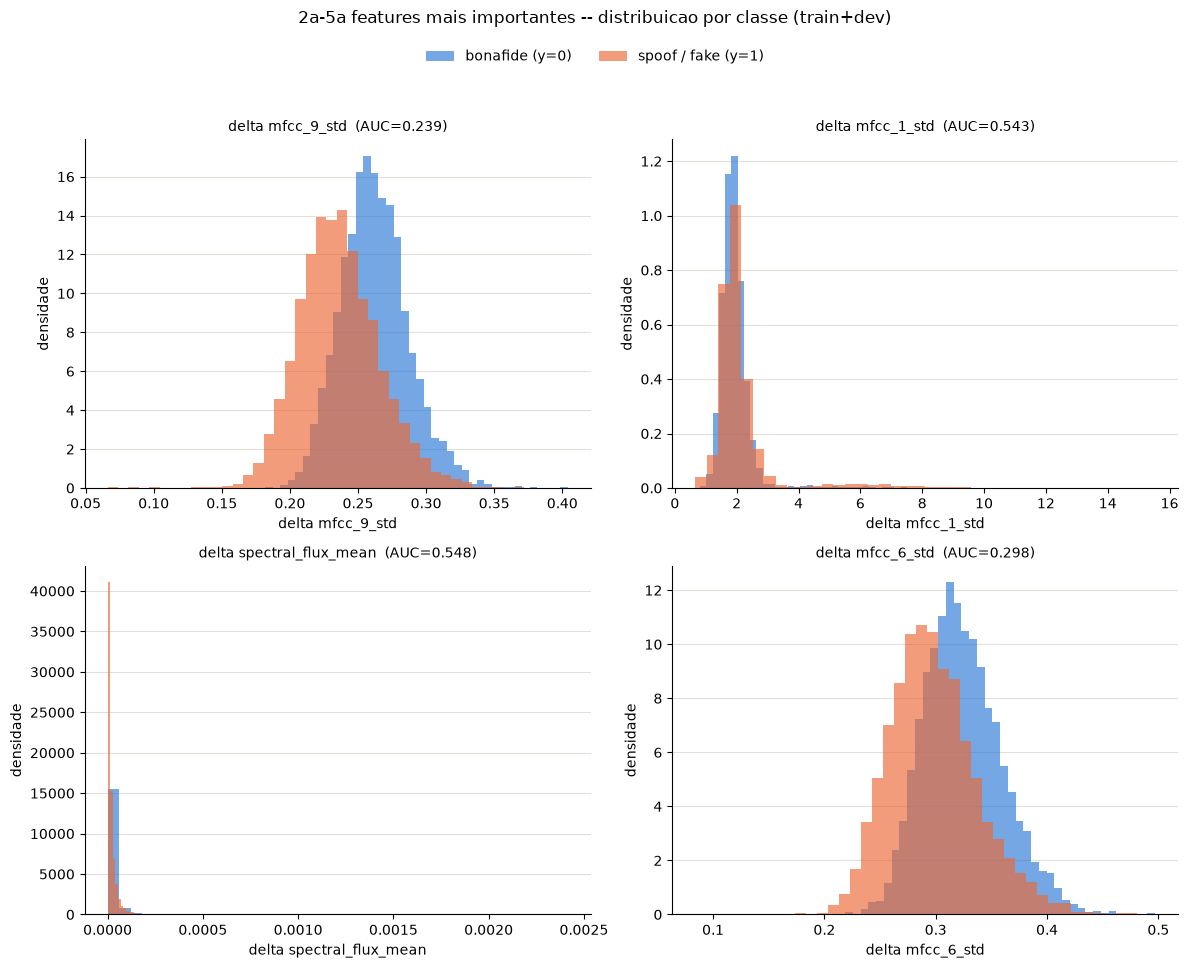

In [178]:
top5_feats = df_imp.sort_values('imp', ascending=False)['feat'].head(5).tolist()
print("Top 5 features por importancia (split-count):", top5_feats)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, feat in zip(axes.ravel(), top5_feats[1:]):
    df_feat = pd.concat([df_train_tabular[[feat, 'y']], df_dev_tabular[[feat, 'y']]])
    ax.hist(df_feat.loc[df_feat['y'] == 0, feat], bins=40, density=True,
            alpha=0.65, color='#2a78d6', label='bonafide (y=0)', zorder=2)
    ax.hist(df_feat.loc[df_feat['y'] == 1, feat], bins=40, density=True,
            alpha=0.65, color='#eb6834', label='spoof / fake (y=1)', zorder=2)
    auc_feat = roc_auc_score(df_feat['y'], df_feat[feat])
    ax.set_title(f"{feat}  (AUC={auc_feat:.3f})", fontsize=10)
    ax.set_xlabel(feat)
    ax.set_ylabel("densidade")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)

handles, labels = axes.ravel()[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("2a-5a features mais importantes -- distribuicao por classe (train+dev)", y=1.07)
plt.tight_layout()
fig.savefig(FIG_DIR / "top5_features_hist.png", dpi=150, bbox_inches="tight")
plt.show()


Feature com maior importancia (split-count) no LightGBM: mfcc_1_mean


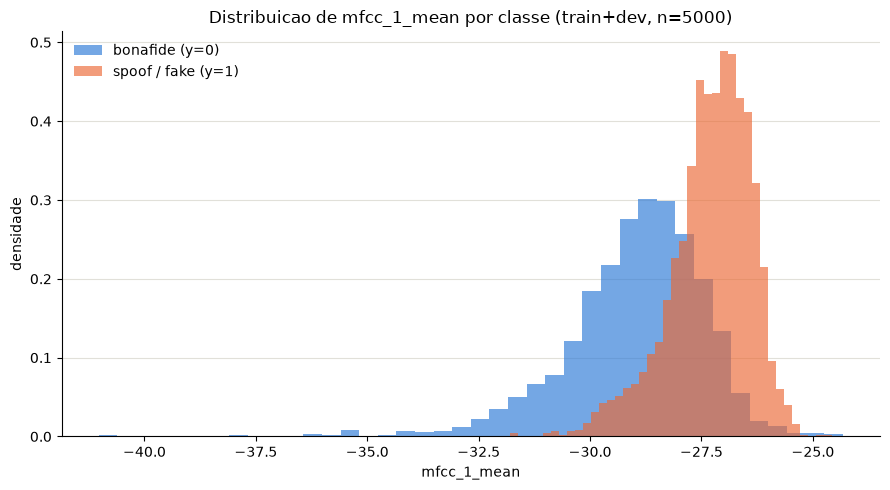

AUC usando SO mfcc_1_mean como score: 0.844  (0.5 = sem poder discriminativo isolado)


In [165]:
import matplotlib.pyplot as plt

top_feat = df_imp.sort_values('imp', ascending=False).iloc[0]['feat']
print(f"Feature com maior importancia (split-count) no LightGBM: {top_feat}")

fig, ax = plt.subplots(figsize=(9, 5))
bins = 40
ax.hist(df_train_tabular.loc[df_train_tabular['y'] == 0, top_feat], bins=bins, density=True,
        alpha=0.65, color='#2a78d6', label='bonafide (y=0)', zorder=2)
ax.hist(df_train_tabular.loc[df_train_tabular['y'] == 1, top_feat], bins=bins, density=True,
        alpha=0.65, color='#eb6834', label='spoof / fake (y=1)', zorder=2)
ax.set_xlabel(top_feat)
ax.set_ylabel("densidade")
ax.set_title(f"Distribuicao de {top_feat} por classe (train+dev, n={len(df_train_tabular)})")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

auc_single_feature = roc_auc_score(df_train_tabular['y'], df_train_tabular[top_feat])
print(f"AUC usando SO {top_feat} como score: {auc_single_feature:.3f}  (0.5 = sem poder discriminativo isolado)")


Feature com maior importancia (split-count) no LightGBM: mfcc_1_mean


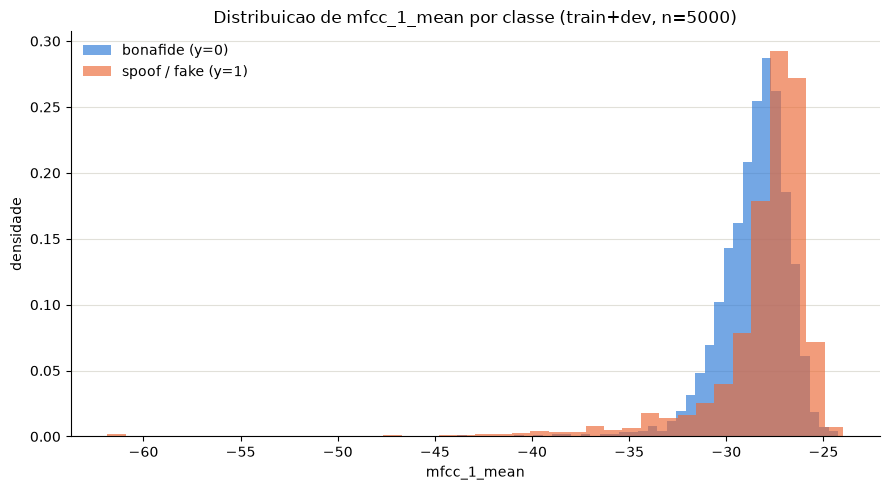

AUC usando SO mfcc_1_mean como score: 0.651  (0.5 = sem poder discriminativo isolado)


In [166]:
import matplotlib.pyplot as plt

top_feat = df_imp.sort_values('imp', ascending=False).iloc[0]['feat']
print(f"Feature com maior importancia (split-count) no LightGBM: {top_feat}")

fig, ax = plt.subplots(figsize=(9, 5))
bins = 40
ax.hist(df_dev_tabular.loc[df_dev_tabular['y'] == 0, top_feat], bins=bins, density=True,
        alpha=0.65, color='#2a78d6', label='bonafide (y=0)', zorder=2)
ax.hist(df_dev_tabular.loc[df_dev_tabular['y'] == 1, top_feat], bins=bins, density=True,
        alpha=0.65, color='#eb6834', label='spoof / fake (y=1)', zorder=2)
ax.set_xlabel(top_feat)
ax.set_ylabel("densidade")
ax.set_title(f"Distribuicao de {top_feat} por classe (train+dev, n={len(df_dev_tabular)})")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

auc_single_feature = roc_auc_score(df_dev_tabular['y'], df_dev_tabular[top_feat])
print(f"AUC usando SO {top_feat} como score: {auc_single_feature:.3f}  (0.5 = sem poder discriminativo isolado)")


In [122]:
import sys, subprocess
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
    import shap

explainer = shap.TreeExplainer(clf)
sv_dev = explainer.shap_values(df_dev_tabular[feat_names])

# normaliza o formato de retorno (varia entre versoes do shap p/ classificador binario):
# lista [classe0, classe1] -> pega a classe positiva (fake); array 3D (n, feats, classes) -> idem
if isinstance(sv_dev, list):
    sv_dev = sv_dev[1]
elif isinstance(sv_dev, np.ndarray) and sv_dev.ndim == 3:
    sv_dev = sv_dev[:, :, 1]


/Users/arthurmoriggipimenta/Desktop/doutorado/ia-adversarial/env_aiadv/lib/python3.13/site-packages/pyAudioAnalysis/../shap/explainers/_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


/var/folders/vn/qwxg6g2j3x363x3hjdxtfnpr0000gn/T/ipykernel_34710/139162671.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_dev, df_dev_tabular[feat_names], max_display=15, show=False)


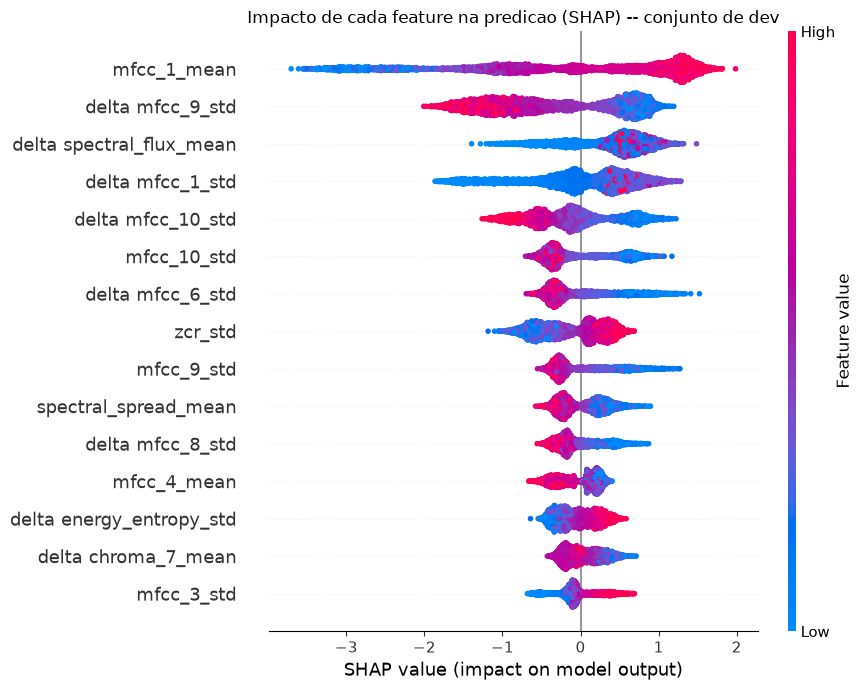

In [167]:
shap.summary_plot(sv_dev, df_dev_tabular[feat_names], max_display=15, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 7)
plt.title("Impacto de cada feature na predicao (SHAP) -- conjunto de dev")
plt.tight_layout()
fig.savefig(FIG_DIR / "shap_summary_gbm.png", dpi=150, bbox_inches="tight")
plt.show()


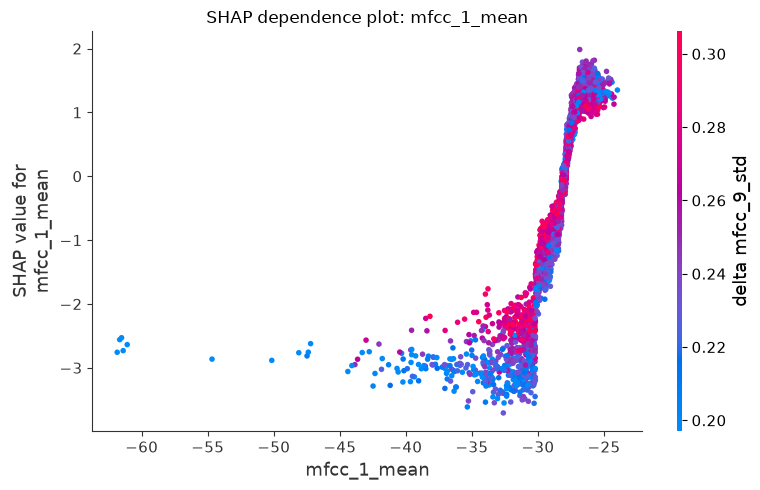

In [168]:
shap.dependence_plot(top_feat, sv_dev, df_dev_tabular[feat_names], show=False)
fig = plt.gcf()
fig.set_size_inches(8, 5)
plt.title(f"SHAP dependence plot: {top_feat}")
plt.tight_layout()
fig.savefig(FIG_DIR / "shap_dependence_mfcc1.png", dpi=150, bbox_inches="tight")
plt.show()


### Vazamento por locutor: StratifiedKFold (aleatorio) vs GroupKFold (por locutor)

O ASVspoof separa locutores entre treino e dev de proposito, pra testar generalizacao. Mas quando fizemos `train_test_split` pra montar `X_val`, ele separou por **linha**, nao por **locutor** -- entao o mesmo locutor (falando o mesmo texto-base, so reprocessado por ataques de spoof diferentes) pode aparecer tanto em `X_train` quanto em `X_val`. Isso deixa a validacao "facil": o modelo ja viu as caracteristicas daquele locutor/canal em outras linhas do treino.

Testamos isso comparando um `StratifiedKFold` comum (ignora locutor) com um `GroupKFold` por locutor (garante que um locutor nunca aparece em treino E validacao ao mesmo tempo dentro do fold).

In [92]:
from sklearn.model_selection import GroupKFold, StratifiedKFold

# recupera o speaker_id de cada arquivo a partir da linha original do protocolo
# (ex: "T_4850 T_0000000000 F - A05 spoof" -> speaker_id = "T_4850")
df_train_files_speaker = df_train_files.copy()
df_train_files_speaker["speaker_id"] = df_train_files_speaker["file_full_name"].apply(lambda s: s.split(" ")[0])

df_cv = df_train_tabular.merge(
    df_train_files_speaker[["file_name", "speaker_id"]], on="file_name", how="left"
)
print(f"locutores distintos na amostra de treino: {df_cv['speaker_id'].nunique()} (de {len(df_cv)} audios)")

X_cv, y_cv, groups_cv = df_cv[feat_names], df_cv["y"], df_cv["speaker_id"]

params_cv = dict(params)
params_cv["n_estimators"] = 200  # fixo e pequeno so pra comparar esquemas de CV -- nao e a busca de hiperparametros

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs_stratified = []
for tr_idx, va_idx in skf.split(X_cv, y_cv):
    m = LGBMClassifier(**params_cv)
    m.fit(X_cv.iloc[tr_idx], y_cv.iloc[tr_idx])
    aucs_stratified.append(roc_auc_score(y_cv.iloc[va_idx], m.predict_proba(X_cv.iloc[va_idx])[:, 1]))

gkf = GroupKFold(n_splits=5)
aucs_group = []
for tr_idx, va_idx in gkf.split(X_cv, y_cv, groups_cv):
    m = LGBMClassifier(**params_cv)
    m.fit(X_cv.iloc[tr_idx], y_cv.iloc[tr_idx])
    aucs_group.append(roc_auc_score(y_cv.iloc[va_idx], m.predict_proba(X_cv.iloc[va_idx])[:, 1]))

print("StratifiedKFold (ignora locutor) -- AUC por fold:", [f"{a:.4f}" for a in aucs_stratified],
      "| media:", f"{np.mean(aucs_stratified):.4f}")
print("GroupKFold (por locutor)        -- AUC por fold:", [f"{a:.4f}" for a in aucs_group],
      "| media:", f"{np.mean(aucs_group):.4f}")

locutores distintos na amostra de treino: 400 (de 5000 audios)
StratifiedKFold (ignora locutor) -- AUC por fold: ['0.9949', '0.9950', '0.9909', '0.9933', '0.9944'] | media: 0.9937
GroupKFold (por locutor)        -- AUC por fold: ['0.9933', '0.9886', '0.9889', '0.9933', '0.9898'] | media: 0.9908


Se a media do `GroupKFold` ficar visivelmente mais baixa que a do `StratifiedKFold` (e mais perto do `AUC (dev)`), confirma a hipotese de vazamento por locutor. Se as duas ficarem parecidas e ainda bem acima do `dev`, o gap e mais sobre diferenca de distribuicao entre o pool de locutores/condicoes do `train` e o pool do `dev` (que no ASVspoof e desenhado pra ser disjunto de proposito) -- nesse caso, nem k-fold por locutor resolve sozinho; ajuda mais regularizar o modelo, usar menos features especificas de locutor/canal, ou validar direto contra uma fatia do proprio `dev`.

## Ouvindo os audios em que o modelo teve mais e menos razao

In [105]:
from pathlib import Path
from IPython.display import Audio, display

DEV_FLAC_DIR = Path("../data/flac_sample/dev")

df_dev_tabular["pred"] = clf.predict_proba(df_dev_tabular[feat_names])[:, 1]
df_dev_tabular["acertou"] = (df_dev_tabular["pred"] >= 0.5).astype(int) == df_dev_tabular["y"]

# fake (y=1) que o modelo identificou com MUITA confianca e acertou
top_fake_certo = df_dev_tabular[
    (df_dev_tabular["y"] == 1) & (df_dev_tabular["acertou"])
].sort_values("pred", ascending=False).head(3)

# bonafide (y=0) que o modelo confundiu com MUITA confianca (achou que era fake)
top_bonafide_errado = df_dev_tabular[
    (df_dev_tabular["y"] == 0) & (~df_dev_tabular["acertou"])
].sort_values("pred", ascending=False).head(3)

# fake (y=1) que o modelo confundiu com MUITA confianca (achou que era bonafide)
top_fake_errado = df_dev_tabular[
    (df_dev_tabular["y"] == 1) & (~df_dev_tabular["acertou"])
].sort_values("pred", ascending=True).head(3)

print("=== Fake, modelo acertou com muita confianca ===")
for _, row in top_fake_certo.iterrows():
    print(f"{row['file_name']} -- pred={row['pred']:.4f} (y=fake)")
    x, Fs = sf.read(str(DEV_FLAC_DIR / row["file_name"]))
    display(Audio(x, rate=Fs,autoplay=True,))

print("\n=== Bonafide que o modelo confundiu com fake (confiante e errado) ===")
for _, row in top_bonafide_errado.iterrows():
    print(f"{row['file_name']} -- pred={row['pred']:.4f} (y=bonafide)")
    x, Fs = sf.read(str(DEV_FLAC_DIR / row["file_name"]))
    display(Audio(x, rate=Fs,autoplay=True,))

print("\n=== Fake que o modelo confundiu com bonafide (confiante e errado) ===")
for _, row in top_fake_errado.iterrows():
    print(f"{row['file_name']} -- pred={row['pred']:.4f} (y=fake)")
    x, Fs = sf.read(str(DEV_FLAC_DIR / row["file_name"]))
    display(Audio(x, rate=Fs,autoplay=True,))

=== Fake, modelo acertou com muita confianca ===
D_0000290830.flac -- pred=0.9999 (y=fake)


D_0000964909.flac -- pred=0.9998 (y=fake)


D_0000509944.flac -- pred=0.9997 (y=fake)



=== Bonafide que o modelo confundiu com fake (confiante e errado) ===
D_0002320522.flac -- pred=0.9972 (y=bonafide)


D_0000864214.flac -- pred=0.9968 (y=bonafide)


D_0000344989.flac -- pred=0.9950 (y=bonafide)



=== Fake que o modelo confundiu com bonafide (confiante e errado) ===
D_0000279322.flac -- pred=0.0003 (y=fake)


D_0002849155.flac -- pred=0.0006 (y=fake)


D_0000171151.flac -- pred=0.0009 (y=fake)


- Identificou fakes com confiança: Audios com ruído robotizado.
- Casos que não conseguiu identificar que eram fakes: Audios cortados mas sem ruído.

# Recurrent Neural Network

Aqui usamos a representacao sequencial (um vetor de features por frame, comprimento variavel por audio) em vez da tabela agregada. Sem busca de hiperparametro com Optuna -- so alguns testes rapidos de arquitetura.

In [125]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

RANDOM_STATE_NN = 42
tf.random.set_seed(RANDOM_STATE_NN)

In [126]:
data_train = np.load("../data/flac_sample/data_prep/train_sequences.npz", allow_pickle=True)
data_dev = np.load("../data/flac_sample/data_prep/dev_sequences.npz", allow_pickle=True)

seq_train_raw = data_train["sequences"]
y_train_seq_full = data_train["labels"].astype("float32")
seq_dev_raw = data_dev["sequences"]
y_dev_seq = data_dev["labels"].astype("float32")

print(f"train: {len(seq_train_raw)} audios | dev: {len(seq_dev_raw)} audios")
print(f"numero de features por frame: {seq_train_raw[0].shape[1]}")

# BUG conhecido do _harmonic_fixed (secao Dataprep): quando gamma vem com NaN (raiz de
# numero negativo), a blindagem "if zcr > 0.15: hr, f0 = 0.0, 0.0" nao pega o caso, porque
# zcr tambem fica NaN e "NaN > 0.15" e sempre False em numpy -- cai no ramo normal e
# "hr = np.max(gamma)" sai NaN. Resultado: a coluna harmonic_ratio (indice 68 de 70) sai
# NaN em praticamente todo frame de todo audio nas sequencias. No tabular isso ja tinha
# sido neutralizado dropando harmonic_ratio_mean/std (feat_names, secao EDA); aqui
# replicamos a mesma exclusao, removendo a coluna da sequencia -- um unico NaN em um
# batch e suficiente pra travar o treino da rede em loss=nan/auc=0.5 (LightGBM tolera
# NaN nativamente, Keras/TensorFlow nao tolera nenhum).
HARMONIC_RATIO_IDX = 68  # f_names_ext = 68 features classicas + ["harmonic_ratio", "f0"]
seq_train_raw = [np.delete(s, HARMONIC_RATIO_IDX, axis=1) for s in seq_train_raw]
seq_dev_raw = [np.delete(s, HARMONIC_RATIO_IDX, axis=1) for s in seq_dev_raw]
print(f"numero de features por frame (apos remover harmonic_ratio com NaN): {seq_train_raw[0].shape[1]}")

# normalizacao (z-score) -- estatisticas calculadas SO com o treino, aplicadas em treino e dev
all_train_frames = np.concatenate(seq_train_raw, axis=0)
frame_mean = all_train_frames.mean(axis=0)
frame_std = all_train_frames.std(axis=0) + 1e-8

seq_train_norm = [(s - frame_mean) / frame_std for s in seq_train_raw]
seq_dev_norm = [(s - frame_mean) / frame_std for s in seq_dev_raw]


train: 5000 audios | dev: 5000 audios
numero de features por frame: 70
numero de features por frame (apos remover harmonic_ratio com NaN): 69


In [127]:
# tamanho fixo de sequencia -- percentil 90 do treino, pra nao deixar poucos
# audios muito longos dominarem o tamanho do padding
lens_train = [len(s) for s in seq_train_norm]
MAX_LEN = int(np.percentile(lens_train, 90))
print(f"MAX_LEN escolhido (percentil 90 dos comprimentos de treino): {MAX_LEN}")

X_train_pad = pad_sequences(seq_train_norm, maxlen=MAX_LEN, dtype="float32", padding="post", truncating="post")
X_dev_pad = pad_sequences(seq_dev_norm, maxlen=MAX_LEN, dtype="float32", padding="post", truncating="post")

# holdout de validacao -- so pra acompanhar o treino, sem otimizar hiperparametro (sem optuna aqui)
X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_train_pad, y_train_seq_full, test_size=0.15, stratify=y_train_seq_full, random_state=RANDOM_STATE_NN
)

N_FEATS = X_train_pad.shape[-1]
print(f"shape de entrada: (batch, {MAX_LEN}, {N_FEATS})")

MAX_LEN escolhido (percentil 90 dos comprimentos de treino): 715
shape de entrada: (batch, 715, 69)


**Arquitetura:** camada de entrada -> (ramo LSTM em paralelo com ramo convolucional) -> concatenacao -> hidden layer -> sigmoide.

In [131]:
inputs = keras.Input(shape=(MAX_LEN, N_FEATS), name="sequence_input")

# ramo recorrente -- Masking ignora os timesteps de padding (zeros) na LSTM
masked = layers.Masking(mask_value=0.0)(inputs)
lstm_branch = layers.LSTM(64)(masked)

# ramo convolucional, em paralelo
conv_branch = layers.Conv1D(filters=64, kernel_size=5, padding="same", activation="relu")(inputs)
conv_branch = layers.GlobalMaxPooling1D()(conv_branch)

# concatena as duas representacoes e classifica
concat = layers.Concatenate()([lstm_branch, conv_branch])
hidden = layers.Dense(32, activation="relu")(concat)
hidden = layers.Dropout(0.3)(hidden)
output = layers.Dense(1, activation="sigmoid")(hidden)

model_rnn = keras.Model(inputs=inputs, outputs=output, name="lstm_conv_parallel")
model_rnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[keras.metrics.AUC(name="auc")],
)
model_rnn.summary()

Model: "lstm_conv_parallel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence_input      │ (None, 715, 69)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 715, 69)   │          0 │ sequence_input[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking_2 (Masking) │ (None, 715, 69)   │          0 │ sequence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_2 (Any)         │ (None, 715)       │          0 │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 715, 64)   │     22,144 │ sequence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 64)        │     34,304 │ masking_2[0][0],  │
│                     │                   │            │ any_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d_4[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 128)       │          0 │ lstm_2[0][0],     │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 32)        │      4,128 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 32)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 1)         │         33 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 60,609 (236.75 KB)

 Trainable params: 60,609 (236.75 KB)

 Non-trainable params: 0 (0.00 B)

In [132]:
history_rnn = model_rnn.fit(
    X_train_nn, y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=10,
    batch_size=32,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True),
    ],
    verbose=1,
)

Epoch 1/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 131ms/step - auc: 0.8630 - loss: 0.4671 - val_auc: 0.9557 - val_loss: 0.2828
Epoch 2/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 17s 128ms/step - auc: 0.9645 - loss: 0.2452 - val_auc: 0.9798 - val_loss: 0.1859
Epoch 3/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 17s 130ms/step - auc: 0.9874 - loss: 0.1522 - val_auc: 0.9868 - val_loss: 0.1494
Epoch 4/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 17s 131ms/step - auc: 0.9955 - loss: 0.0903 - val_auc: 0.9901 - val_loss: 0.1211
Epoch 5/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 17s 131ms/step - auc: 0.9988 - loss: 0.0525 - val_auc: 0.9849 - val_loss: 0.2080
Epoch 6/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 17s 130ms/step - auc: 0.9979 - loss: 0.0552 - val_auc: 0.9889 - val_loss: 0.1743


In [133]:
dev_pred_rnn = model_rnn.predict(X_dev_pad).ravel()
dev_auc_rnn = roc_auc_score(y_dev_seq, dev_pred_rnn)

print(f"""
AUC (train): {roc_auc_score(y_train_nn, model_rnn.predict(X_train_nn).ravel()):.4f}
AUC (val):   {roc_auc_score(y_val_nn, model_rnn.predict(X_val_nn).ravel()):.4f}
AUC (dev):   {dev_auc_rnn:.4f}
""")

157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step
133/133 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step

AUC (train): 0.9997
AUC (val):   0.9907
AUC (dev):   0.6072



# Attention

Mesma ideia da secao de RNN (ramo sequencial + ramo convolucional em paralelo, concatenados e classificados), mas o ramo recorrente (LSTM) e trocado por um ramo de self-attention (`MultiHeadAttention`). Reaproveita os dados ja normalizados e com padding (`X_train_nn`, `X_val_nn`, `X_dev_pad`, `y_train_nn`, `y_val_nn`, `y_dev_seq`) da secao anterior.

In [136]:
inputs_attn = keras.Input(shape=(MAX_LEN, N_FEATS), name="sequence_input_attn")

# ramo de atencao -- self-attention sobre a sequencia, seguido de pooling
attn_branch = layers.MultiHeadAttention(num_heads=4, key_dim=16)(inputs_attn, inputs_attn)
attn_branch = layers.GlobalAveragePooling1D()(attn_branch)
# obs.: por simplicidade (e so um teste rapido), nao aplicamos uma attention_mask
# explicita pro padding aqui -- os frames de padding (zeros) entram na atencao.
# se o resultado vier ruim, vale revisar isso com uma mascara baseada no
# comprimento real de cada audio.

# ramo convolucional, em paralelo (igual ao da secao de RNN)
conv_branch_attn = layers.Conv1D(filters=64, kernel_size=5, padding="same", activation="relu")(inputs_attn)
conv_branch_attn = layers.GlobalMaxPooling1D()(conv_branch_attn)

concat_attn = layers.Concatenate()([attn_branch, conv_branch_attn])
hidden_attn = layers.Dense(32, activation="relu")(concat_attn)
hidden_attn = layers.Dropout(0.3)(hidden_attn)
output_attn = layers.Dense(1, activation="sigmoid")(hidden_attn)

model_attn = keras.Model(inputs=inputs_attn, outputs=output_attn, name="attention_conv_parallel")
model_attn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[keras.metrics.AUC(name="auc")],
)
model_attn.summary()

Model: "attention_conv_parallel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence_input_attn │ (None, 715, 69)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 715, 69)   │     17,925 │ sequence_input_a… │
│ (MultiHeadAttentio… │                   │            │ sequence_input_a… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 715, 64)   │     22,144 │ sequence_input_a… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 69)        │          0 │ multi_head_atten… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d_6[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 133)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 32)        │      4,288 │ concatenate_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 32)        │          0 │ dense_12[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 1)         │         33 │ dropout_10[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 44,390 (173.40 KB)

 Trainable params: 44,390 (173.40 KB)

 Non-trainable params: 0 (0.00 B)

In [137]:
history_attn = model_attn.fit(
    X_train_nn, y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=10,
    batch_size=32,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True),
    ],
    verbose=1,
)

Epoch 1/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 20s 142ms/step - auc: 0.8673 - loss: 0.4558 - val_auc: 0.9636 - val_loss: 0.2642
Epoch 2/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 140ms/step - auc: 0.9660 - loss: 0.2373 - val_auc: 0.9809 - val_loss: 0.2128
Epoch 3/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 140ms/step - auc: 0.9845 - loss: 0.1595 - val_auc: 0.9865 - val_loss: 0.1529
Epoch 4/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 141ms/step - auc: 0.9924 - loss: 0.1116 - val_auc: 0.9886 - val_loss: 0.1359
Epoch 5/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 141ms/step - auc: 0.9968 - loss: 0.0732 - val_auc: 0.9888 - val_loss: 0.1825
Epoch 6/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 140ms/step - auc: 0.9987 - loss: 0.0492 - val_auc: 0.9919 - val_loss: 0.1602
Epoch 7/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 19s 140ms/step - auc: 0.9995 - loss: 0.0341 - val_auc: 0.9934 - val_loss: 0.0980
Epoch 8/10
133/133 ━━━━━━━━━━━━━━━━━━━━ 18s 139ms/step - auc: 0.9996 - loss: 0.0283 - val_auc: 0.9930 - val_loss: 0.1129
Epoch 9/10
133/133 ━━━━━━━━━━━━━

In [138]:
dev_pred_attn = model_attn.predict(X_dev_pad).ravel()
dev_auc_attn = roc_auc_score(y_dev_seq, dev_pred_attn)

print(f"""
AUC (train): {roc_auc_score(y_train_nn, model_attn.predict(X_train_nn).ravel()):.4f}
AUC (val):   {roc_auc_score(y_val_nn, model_attn.predict(X_val_nn).ravel()):.4f}
AUC (dev):   {dev_auc_attn:.4f}
""")

157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step
133/133 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step

AUC (train): 1.0000
AUC (val):   0.9944
AUC (dev):   0.6607



# Por que o Gradient Boosting generalizou melhor que RNN e Attention?

RNN: AUC de val ~0.99, mas cai pra ~0.60 no dev. Attention: ~0.66 no dev. O Gradient Boosting tambem perde performance do treino pro dev, mas bem menos. A pista: `mfcc_1_mean` sozinha (a feature mais importante do GBM) ja da AUC bem diferente em treino e em dev. Investigamos usando o `attack_id` de cada audio (vem no metadata do ASVspoof5, mas ainda nao tinha sido usado em nenhuma celula).

In [141]:
def load_attack_map(path):
    m = {}
    with open(path) as f:
        for line in f:
            parts = line.split()
            file_id, attack_id = parts[1], parts[4]
            m[file_id + ".flac"] = attack_id
    return m

attack_map_train = load_attack_map("../data/ASVspoof5.train.metadata.txt")
attack_map_dev = load_attack_map("../data/ASVspoof5.dev.metadata.txt")

df_train_tabular["attack_id"] = df_train_tabular["file_name"].map(attack_map_train)
df_dev_tabular["attack_id"] = df_dev_tabular["file_name"].map(attack_map_dev)

train_attacks = sorted(set(df_train_tabular["attack_id"]) - {"bonafide"})
dev_attacks = sorted(set(df_dev_tabular["attack_id"]) - {"bonafide"})
print("Sistemas de ataque (spoof) no TREINO:", train_attacks)
print("Sistemas de ataque (spoof) no DEV:   ", dev_attacks)
print("Intersecao treino/dev:", sorted(set(train_attacks) & set(dev_attacks)) or "(nenhuma -- ataques completamente diferentes!)")


Sistemas de ataque (spoof) no TREINO: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08']
Sistemas de ataque (spoof) no DEV:    ['A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16']
Intersecao treino/dev: (nenhuma -- ataques completamente diferentes!)


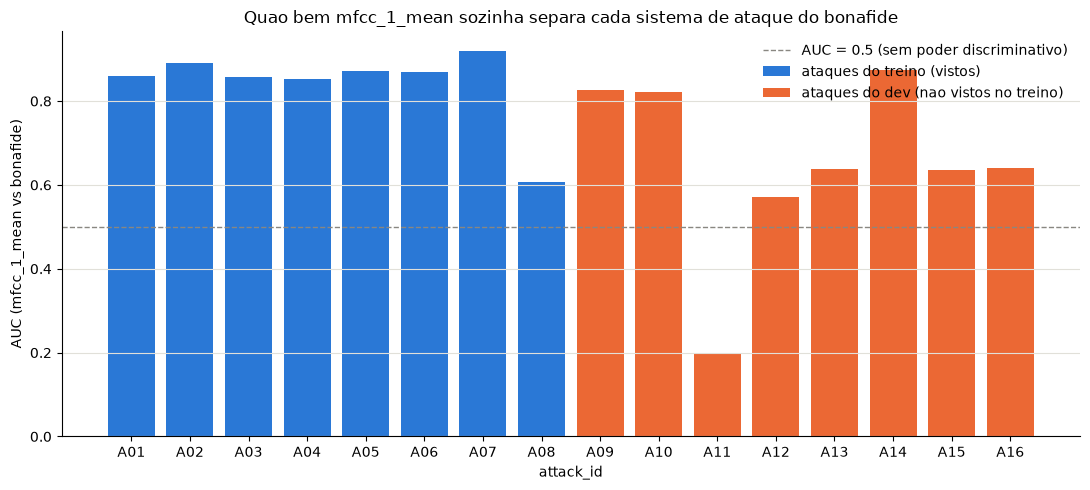


AUC geral de mfcc_1_mean:  treino=0.844   dev=0.651


In [169]:
def per_attack_auc(df, feat):
    bonafide_vals = df.loc[df["y"] == 0, feat]
    rows = []
    for atk, group in df[df["y"] == 1].groupby("attack_id"):
        scores = pd.concat([bonafide_vals, group[feat]])
        labels = pd.concat([pd.Series(0, index=bonafide_vals.index), pd.Series(1, index=group.index)])
        rows.append({"attack_id": atk, "n": len(group), "auc": roc_auc_score(labels, scores)})
    return pd.DataFrame(rows).sort_values("attack_id")

auc_train_by_attack = per_attack_auc(df_train_tabular, top_feat)
auc_dev_by_attack = per_attack_auc(df_dev_tabular, top_feat)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(auc_train_by_attack["attack_id"], auc_train_by_attack["auc"], color="#2a78d6", label="ataques do treino (vistos)")
ax.bar(auc_dev_by_attack["attack_id"], auc_dev_by_attack["auc"], color="#eb6834", label="ataques do dev (nao vistos no treino)")
ax.axhline(0.5, color="#898781", linestyle="--", linewidth=1, label="AUC = 0.5 (sem poder discriminativo)")
ax.set_ylabel(f"AUC ({top_feat} vs bonafide)")
ax.set_xlabel("attack_id")
ax.set_title(f"Quao bem {top_feat} sozinha separa cada sistema de ataque do bonafide")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "attack_id_per_feature_auc.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nAUC geral de {top_feat}:  treino={roc_auc_score(df_train_tabular['y'], df_train_tabular[top_feat]):.3f}   dev={roc_auc_score(df_dev_tabular['y'], df_dev_tabular[top_feat]):.3f}")


133/133 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step
133/133 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step


,modelo,treino,val,dev
0,Gradient Boosting,1.000000,0.993764,0.739229
1,RNN (LSTM+Conv),0.999656,0.990656,0.607180
2,Attention,0.999996,0.994411,0.660714


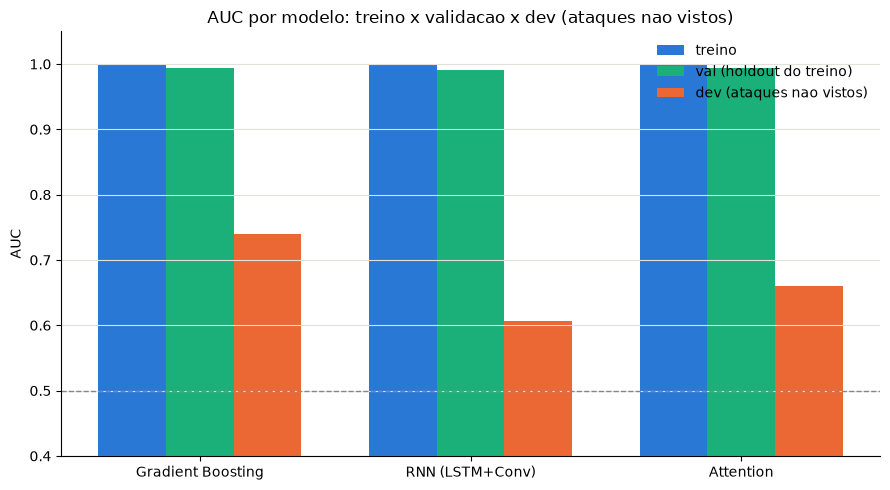

In [170]:
auc_train_gbm = roc_auc_score(y_train, clf.predict_proba(X_train)[:, 1])
auc_val_gbm = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
auc_dev_gbm = roc_auc_score(df_dev_tabular["y"], df_dev_tabular["pred"])

auc_train_rnn = roc_auc_score(y_train_nn, model_rnn.predict(X_train_nn).ravel())
auc_val_rnn = roc_auc_score(y_val_nn, model_rnn.predict(X_val_nn).ravel())

auc_train_attn = roc_auc_score(y_train_nn, model_attn.predict(X_train_nn).ravel())
auc_val_attn = roc_auc_score(y_val_nn, model_attn.predict(X_val_nn).ravel())

summary_auc = pd.DataFrame({
    "modelo": ["Gradient Boosting", "RNN (LSTM+Conv)", "Attention"],
    "treino": [auc_train_gbm, auc_train_rnn, auc_train_attn],
    "val":    [auc_val_gbm, auc_val_rnn, auc_val_attn],
    "dev":    [auc_dev_gbm, dev_auc_rnn, dev_auc_attn],
})
display(summary_auc)

x = np.arange(len(summary_auc))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width, summary_auc["treino"], width, label="treino", color="#2a78d6")
ax.bar(x,         summary_auc["val"],    width, label="val (holdout do treino)", color="#1baf7a")
ax.bar(x + width, summary_auc["dev"],    width, label="dev (ataques nao vistos)", color="#eb6834")
ax.axhline(0.5, color="#898781", linestyle="--", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(summary_auc["modelo"])
ax.set_ylabel("AUC")
ax.set_ylim(0.4, 1.05)
ax.set_title("AUC por modelo: treino x validacao x dev (ataques nao vistos)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "auc_by_model.png", dpi=150, bbox_inches="tight")
plt.show()


## As redes dependem mais de `mfcc_1` que o Gradient Boosting?


In [171]:
def shuffle_and_auc_gbm(df, cols_to_shuffle, seed=42):
    rng = np.random.default_rng(seed)
    baseline_auc = roc_auc_score(df["y"], clf.predict_proba(df[feat_names])[:, 1])
    df_perm = df.copy()
    perm_idx = rng.permutation(len(df_perm))
    for col in cols_to_shuffle:
        df_perm[col] = df_perm[col].values[perm_idx]
    auc_perm = roc_auc_score(df_perm["y"], clf.predict_proba(df_perm[feat_names])[:, 1])
    return baseline_auc - auc_perm, baseline_auc

mfcc1_cols_gbm = [c for c in feat_names if c in ("mfcc_1_mean", "mfcc_1_std")]
drop_gbm, base_auc_gbm = shuffle_and_auc_gbm(df_dev_tabular, mfcc1_cols_gbm)
print(f"Gradient Boosting -- AUC base (dev): {base_auc_gbm:.3f} | queda ao embaralhar {mfcc1_cols_gbm}: {drop_gbm:.4f}")


Gradient Boosting -- AUC base (dev): 0.739 | queda ao embaralhar ['mfcc_1_mean', 'mfcc_1_std']: 0.0488


In [149]:
SHORT_NAMES = ["zcr", "energy", "energy_entropy", "spectral_centroid", "spectral_spread",
               "spectral_entropy", "spectral_flux", "spectral_rolloff"] + \
              [f"mfcc_{k}" for k in range(1, 14)] + \
              [f"chroma_{k}" for k in range(1, 13)] + ["chroma_std"]
SEQ_FEAT_NAMES = SHORT_NAMES + ["delta " + n for n in SHORT_NAMES] + ["f0"]  # harmonic_ratio ja foi removida (secao RNN)
assert len(SEQ_FEAT_NAMES) == N_FEATS, (len(SEQ_FEAT_NAMES), N_FEATS)
MFCC1_SEQ_IDX = SEQ_FEAT_NAMES.index("mfcc_1")

def shuffle_and_auc_seq(model, X, y, feat_idx, seed=42):
    rng = np.random.default_rng(seed)
    baseline_pred = model.predict(X, verbose=0).ravel()
    baseline_auc = roc_auc_score(y, baseline_pred)
    X_perm = X.copy()
    perm_idx = rng.permutation(len(X_perm))
    X_perm[:, :, feat_idx] = X_perm[perm_idx, :, feat_idx]
    perm_pred = model.predict(X_perm, verbose=0).ravel()
    perm_auc = roc_auc_score(y, perm_pred)
    return baseline_auc - perm_auc, baseline_auc

# amostra do dev, pra nao deixar lento
sample_idx = np.random.default_rng(42).choice(len(X_dev_pad), size=min(2000, len(X_dev_pad)), replace=False)
X_dev_sample = X_dev_pad[sample_idx]
y_dev_sample = y_dev_seq[sample_idx]

drop_rnn, base_auc_rnn = shuffle_and_auc_seq(model_rnn, X_dev_sample, y_dev_sample, MFCC1_SEQ_IDX)
drop_attn, base_auc_attn = shuffle_and_auc_seq(model_attn, X_dev_sample, y_dev_sample, MFCC1_SEQ_IDX)

print(f"RNN       -- AUC base (amostra dev): {base_auc_rnn:.3f} | queda ao embaralhar mfcc_1: {drop_rnn:.4f}")
print(f"Attention -- AUC base (amostra dev): {base_auc_attn:.3f} | queda ao embaralhar mfcc_1: {drop_attn:.4f}")


RNN       -- AUC base (amostra dev): 0.609 | queda ao embaralhar mfcc_1: 0.0577
Attention -- AUC base (amostra dev): 0.656 | queda ao embaralhar mfcc_1: 0.0774


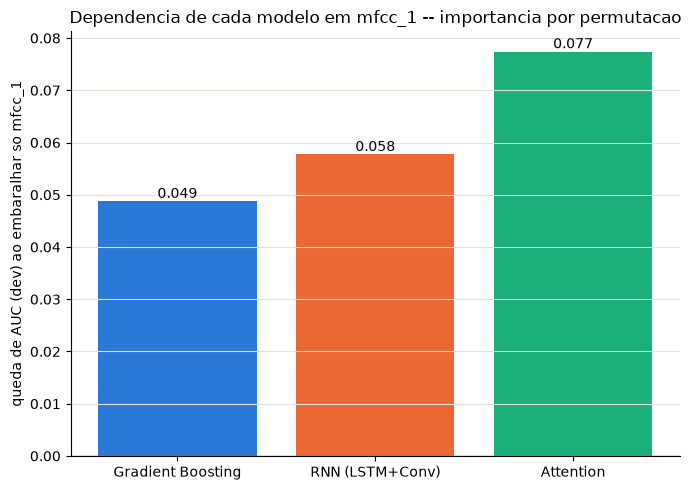

In [172]:
fig, ax = plt.subplots(figsize=(7, 5))
models = ["Gradient Boosting", "RNN (LSTM+Conv)", "Attention"]
drops = [drop_gbm, drop_rnn, drop_attn]
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
bars = ax.bar(models, drops, color=colors)
ax.axhline(0, color="#898781", linewidth=1)
ax.set_ylabel("queda de AUC (dev) ao embaralhar so mfcc_1")
ax.set_title("Dependencia de cada modelo em mfcc_1 -- importancia por permutacao")
for b, d in zip(bars, drops):
    ax.text(b.get_x() + b.get_width() / 2, d, f"{d:.3f}", ha="center", va="bottom" if d >= 0 else "top")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
plt.tight_layout()
fig.savefig(FIG_DIR / "permutation_mfcc1.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
def shap_feature_importance_seq(model, X_background, X_explain, n_background=100, n_explain=300, seed=42):
    rng = np.random.default_rng(seed)
    bg_idx = rng.choice(len(X_background), size=min(n_background, len(X_background)), replace=False)
    ex_idx = rng.choice(len(X_explain), size=min(n_explain, len(X_explain)), replace=False)
    explainer = shap.GradientExplainer(model, X_background[bg_idx])
    sv = explainer.shap_values(X_explain[ex_idx])
    if isinstance(sv, list):
        sv = sv[0]
    sv = np.asarray(sv)
    if sv.ndim == 4:  # (n, timesteps, feats, n_outputs) em algumas versoes do shap
        sv = sv[..., 0]
    feat_importance = np.abs(sv).sum(axis=1).mean(axis=0)  # soma |shap| no tempo, media nas amostras
    return feat_importance

try:
    imp_rnn_shap = shap_feature_importance_seq(model_rnn, X_train_nn, X_dev_pad)
    imp_attn_shap = shap_feature_importance_seq(model_attn, X_train_nn, X_dev_pad)
    shap_seq_ok = True
except Exception as e:
    print(f"GradientExplainer falhou ({type(e).__name__}: {e}) -- a prova por permutacao acima ja e suficiente; "
          f"versao incompativel de shap/tensorflow e a causa mais comum desse erro.")
    shap_seq_ok = False


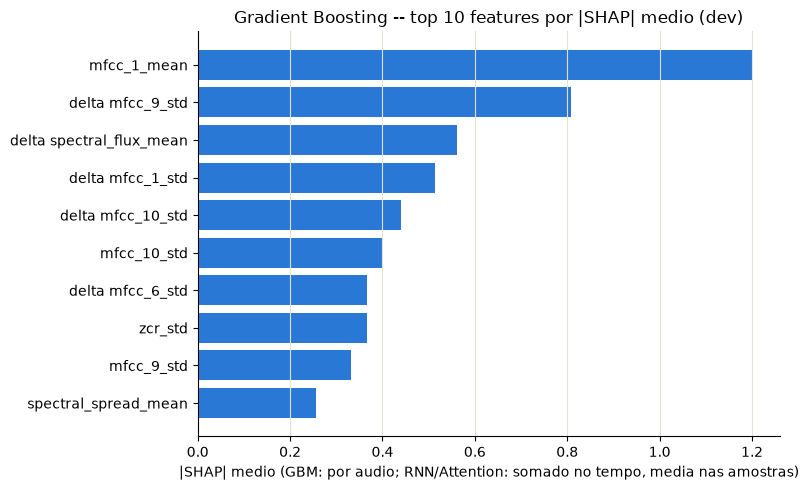

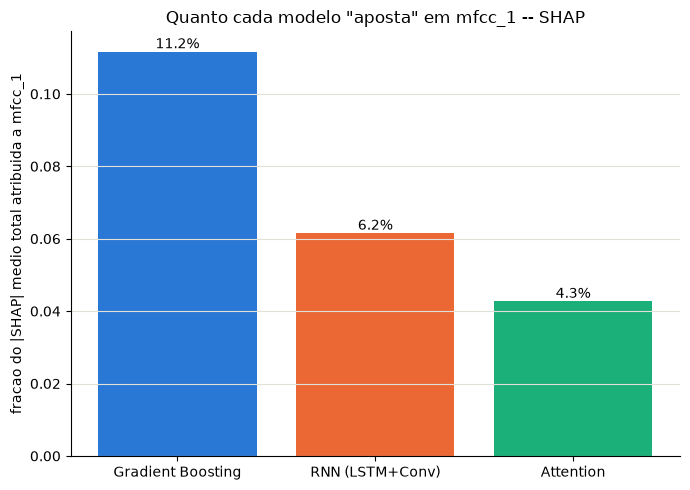

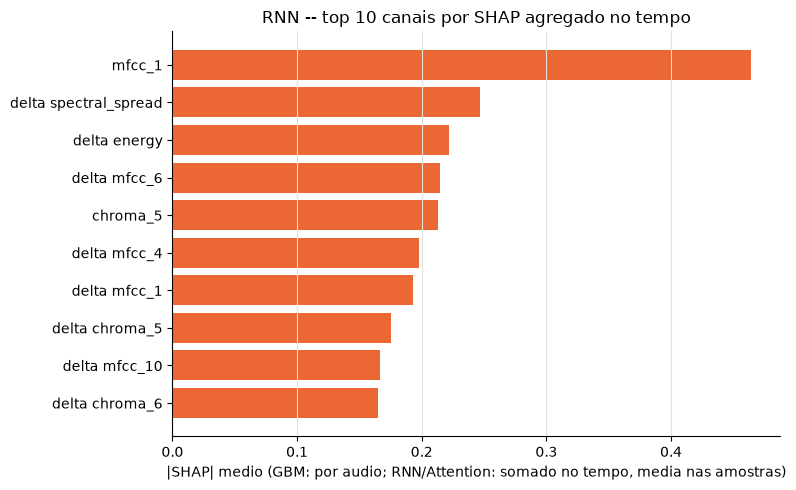

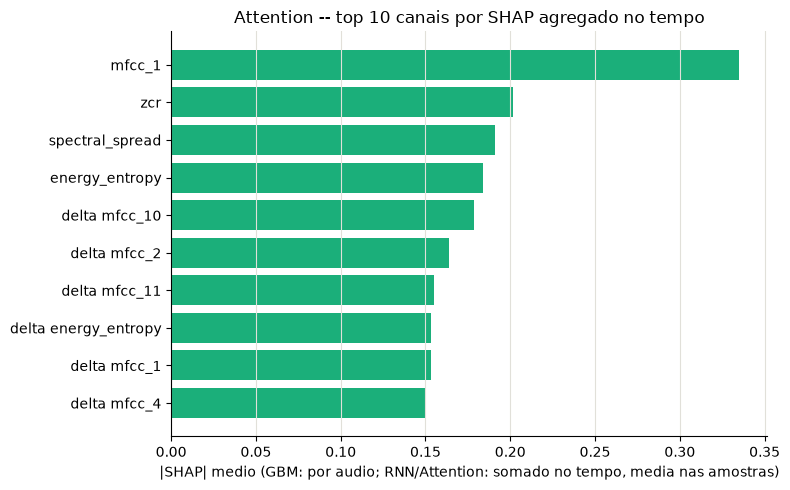

In [174]:
gbm_imp_series = pd.Series(np.abs(sv_dev).mean(axis=0), index=feat_names)

def plot_seq_shap_ranking(importance, names, title, color, filename=None):
    order = np.argsort(importance)[::-1][:10]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh([names[i] for i in order][::-1], importance[order][::-1], color=color)
    ax.set_xlabel("|SHAP| medio (GBM: por audio; RNN/Attention: somado no tempo, media nas amostras)")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e1e0d9", linewidth=0.8, zorder=0)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

# GBM -- sempre da pra plotar, independe do GradientExplainer das redes ter funcionado
plot_seq_shap_ranking(gbm_imp_series.values, list(gbm_imp_series.index),
                       "Gradient Boosting -- top 10 features por |SHAP| medio (dev)", "#2a78d6",
                       "shap_top10_gbm.png")

if shap_seq_ok:
    mfcc1_gbm_share = gbm_imp_series.reindex(mfcc1_cols_gbm).sum() / gbm_imp_series.sum()
    mfcc1_rnn_share = imp_rnn_shap[MFCC1_SEQ_IDX] / imp_rnn_shap.sum()
    mfcc1_attn_share = imp_attn_shap[MFCC1_SEQ_IDX] / imp_attn_shap.sum()

    fig, ax = plt.subplots(figsize=(7, 5))
    shares = [mfcc1_gbm_share, mfcc1_rnn_share, mfcc1_attn_share]
    bars = ax.bar(models, shares, color=colors)
    ax.set_ylabel("fracao do |SHAP| medio total atribuida a mfcc_1")
    ax.set_title("Quanto cada modelo \"aposta\" em mfcc_1 -- SHAP")
    for b, s in zip(bars, shares):
        ax.text(b.get_x() + b.get_width() / 2, s, f"{s:.1%}", ha="center", va="bottom")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
    plt.tight_layout()
    fig.savefig(FIG_DIR / "shap_share_mfcc1.png", dpi=150, bbox_inches="tight")
    plt.show()

    plot_seq_shap_ranking(imp_rnn_shap, SEQ_FEAT_NAMES, "RNN -- top 10 canais por SHAP agregado no tempo",
                           "#eb6834", "shap_top10_rnn.png")
    plot_seq_shap_ranking(imp_attn_shap, SEQ_FEAT_NAMES, "Attention -- top 10 canais por SHAP agregado no tempo",
                           "#1baf7a", "shap_top10_attention.png")
